<a href="https://colab.research.google.com/github/Myllertg/RiscoDeCredito/blob/main/RiscoDeCredito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 1. Entendimento do Negócio (Business Understanding)

O projeto **German Credit Risk** tem como objetivo desenvolver um modelo de Machine Learning capaz de classificar o risco de crédito de clientes, identificando aqueles que apresentam maior probabilidade de inadimplência.

No mercado financeiro, a concessão de crédito envolve decisões que precisam equilibrar oportunidades de negócio e exposição ao risco. Uma avaliação inadequada pode resultar em perdas financeiras, enquanto critérios excessivamente restritivos podem impedir a aprovação de bons clientes.

Nesse contexto, a proposta é utilizar dados históricos de clientes e informações relacionadas às suas operações de crédito para identificar padrões associados ao comportamento de pagamento.

### Objetivos do projeto

- Analisar as características dos clientes e suas operações de crédito.
- Identificar padrões relacionados ao risco de inadimplência.
- Desenvolver modelos preditivos para classificar clientes conforme o risco de crédito.
- Comparar o desempenho de diferentes algoritmos de Machine Learning.
- Criar uma aplicação interativa para demonstrar a utilização do modelo na avaliação de novos casos.

### Resultado esperado

Construir uma solução analítica que demonstre como a Ciência de Dados pode apoiar o processo de avaliação de crédito, contribuindo para decisões mais fundamentadas, melhor identificação de riscos e redução da exposição à inadimplência.

O modelo tem finalidade demonstrativa e educacional, não substituindo uma política real de concessão de crédito ou uma análise financeira completa.


In [1]:
#Instalação de API
!pip install -q kaggle

#Importação das Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from pathlib import Path
from sklearn.preprocessing import LabelEncoder
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV,cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone


In [2]:
# CONFIGURAÇÃO DOS DIRETÓRIOS
DATA_DIR = Path("./data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Identificador do dataset no Kaggle
DATASET = "kabure/german-credit-data-with-risk"

# DOWNLOAD DO DATASET
!kaggle datasets download -d {DATASET} -p {DATA_DIR}

#IDENTIFICAÇÃO DO ARQUIVO ZIP
zip_files = list(DATA_DIR.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        "Nenhum arquivo ZIP foi encontrado após o download."
    )
ZIP_PATH = zip_files[0]

print("DOWNLOAD CONCLUÍDO")
print(f"Dataset: {DATASET}")
print(f"Arquivo: {ZIP_PATH.name}")

#EXTRAÇÃO DOS ARQUIVOS
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("\nArquivos extraídos:")

for file in DATA_DIR.iterdir():
    if file.is_file():
        print(f" - {file.name}")

#IDENTIFICAÇÃO DO ARQUIVO CSV
csv_files = list(DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "Nenhum arquivo CSV foi encontrado após a extração."
    )

CSV_PATH = csv_files[0]

#CARREGAMENTO DOS DADOS
df = pd.read_csv(CSV_PATH)

pd.set_option("display.max_columns", None)

sns.set_style("whitegrid")

Dataset URL: https://www.kaggle.com/datasets/kabure/german-credit-data-with-risk
License(s): CC0-1.0
100% 11.2k/11.2k [00:00<00:00, 19.4MB/s]

DOWNLOAD CONCLUÍDO
Dataset: kabure/german-credit-data-with-risk
Arquivo: german-credit-data-with-risk.zip

Arquivos extraídos:
 - german_credit_data.csv
 - german-credit-data-with-risk.zip



# 2. Entendimento dos Dados (Data Understanding)

Nesta etapa, o objetivo é conhecer a estrutura e as características do conjunto de dados utilizado no projeto. Será realizada uma análise exploratória para identificar as variáveis disponíveis, compreender suas distribuições, verificar a qualidade das informações e identificar possíveis valores ausentes ou inconsistências.

Essa investigação permite compreender melhor os dados e identificar os ajustes necessários para as próximas etapas do projeto.


In [3]:
# Verificação da coluna Risk
print("- DISTRIBUIÇÃO DO RISCO DE CRÉDITO -")
print(df["Risk"].value_counts())

print("\n-----------------------------------\n")


#Visualização das Colunas existentes
print("- COLUNAS EXISTENTES -")
print(df.columns)

print("\n-----------------------------------\n")

# Informações sobre o banco de dados
print("- INFORMAÇÕES DO DATAFRAME -")
df.info()

print("\n-----------------------------------\n")

#Estatísticas descritivas das variáveis
print("- ESTÁTISTICAS DESCRITIVAS -")
display(df.describe(include="all").T)

print("\n-----------------------------------\n")

#Analise da Coluna Trabalho
print("- ANÁLISE DA COLUNA TRABALHO -")
display(df["Job"].unique())

print("\n-----------------------------------\n")


# Valores Nulos
print("- VALORES NULOS -")
display(df.isna().sum())

print("\n-----------------------------------\n")

#Valores Duplicados
print("- VALORES Duplicados -")
display(df.duplicated().sum())

- DISTRIBUIÇÃO DO RISCO DE CRÉDITO -
Risk
good    700
bad     300
Name: count, dtype: int64

-----------------------------------

- COLUNAS EXISTENTES -
Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

-----------------------------------

- INFORMAÇÕES DO DATAFRAME -
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving accounts   817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,NaN,NaN,NaN,499.5,288.819436,0.0,249.75,499.5,749.25,999.0
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN



-----------------------------------

- ANÁLISE DA COLUNA TRABALHO -


array([2, 1, 3, 0])


-----------------------------------

- VALORES NULOS -


,0
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0



-----------------------------------

- VALORES Duplicados -


np.int64(0)


Nesta etapa, foi realizada uma análise exploratória dos dados (EDA) com o objetivo de conhecer a estrutura, as características e a qualidade das informações disponíveis no dataset German Credit Risk.

Inicialmente, foram verificadas as colunas existentes, as dimensões do DataFrame e os tipos de dados de cada variável, permitindo identificar características que poderão exigir ajustes durante a preparação dos dados.

### Principais descobertas

- **Distribuição do risco de crédito:** foram identificados aproximadamente 700 registros classificados como `good` (bom risco de crédito) e 300 como `bad` (mau risco de crédito). Essa distribuição representa uma proporção de 70% e 30%, respectivamente, indicando um desbalanceamento entre as classes que deverá ser considerado na modelagem.

- **Tipos de dados:** a inspeção do DataFrame permitiu identificar variáveis numéricas e categóricas, além de campos que poderão necessitar de conversão ou adequação de tipo na etapa de preparação.

- **Valores ausentes:** foram identificados valores nulos concentrados principalmente nas variáveis `Saving accounts`, com 183 registros ausentes, e `Checking account`, com 394 registros ausentes.

- **Variável Job:** foi identificada uma classificação numérica representada pelos valores 0, 1, 2 e 3, indicando diferentes categorias profissionais.

- **Registros duplicados:** não foram identificados registros duplicados na base de dados.



# 3. Preparação dos Dados (Data Preparation)

Nesta etapa, será realizada a identificação e a separação das variáveis categóricas do conjunto de dados, incluindo `Sex`, `Job`, `Housing`, `Saving accounts`, `Checking account` e `Purpose`.

Também será removidos os registros que apresentavam valores ausentes (`NaN`), com o objetivo de trabalhar inicialmente com uma base completa. Por fim, foi excluída a coluna `Unnamed: 0`, que corresponde a um identificador sem relevância para a análise e a modelagem.



In [4]:
#Definição das variáveis categóricas
categorical_cols = [
    "Sex",
    "Job",
    "Housing",
    "Saving accounts",
    "Checking account",
    "Purpose"
]

#Remoção dos registros com valores ausentes
df = df.dropna().reset_index(drop=True)

#Remoção da coluna de identificação, caso exista
df.drop(
    columns="Unnamed: 0",
    inplace=True,
    errors="ignore"
)


## Análise Exploratória dos Dados (EDA)

Após a análise inicial da estrutura e da qualidade do conjunto de dados, será realizada uma investigação mais aprofundada por meio de gráficos, tabelas e análises estatísticas. O objetivo é compreender melhor a distribuição das variáveis, identificar padrões e possíveis relações entre as características dos clientes e a classificação de risco de crédito (`Risk`).

Essa etapa permitirá extrair informações relevantes do conjunto de dados, identificar comportamentos e levantar hipóteses que poderão orientar as próximas etapas de preparação e modelagem.

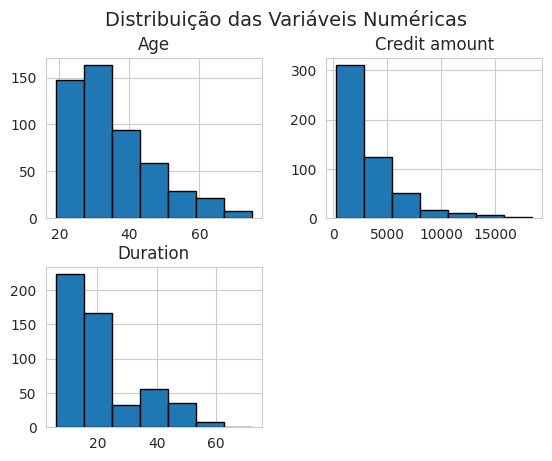

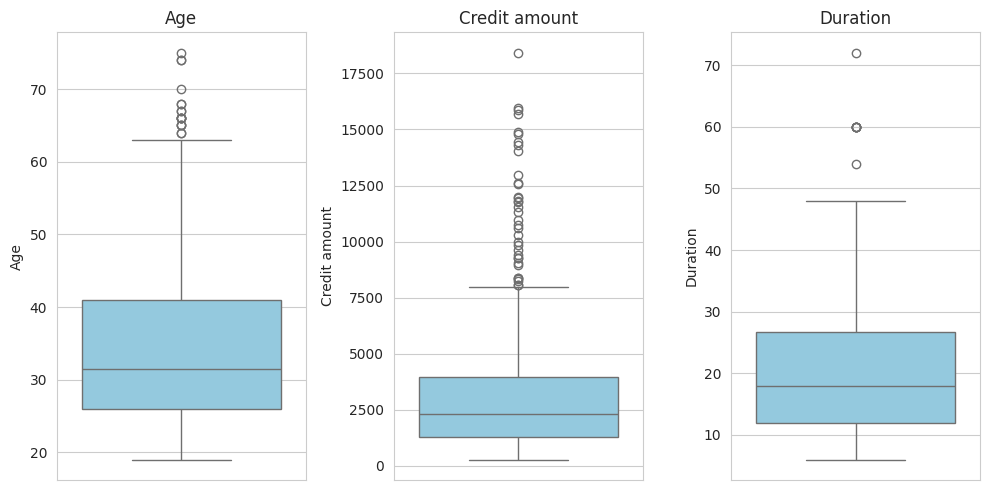

In [5]:

#Histograma das variáveis numéricas
df[["Age", "Credit amount","Duration"]].hist(bins = 7, edgecolor ="black")
plt.suptitle("Distribuição das Variáveis Numéricas", fontsize = 14)
plt.show


#IDENTIFICAÇÃO DE OUTLIERS COM BOXPLOTS
plt.figure(figsize= (10,5))
for i, col in enumerate (["Age", "Credit amount", "Duration"]):
  plt.subplot(1,3,i+1)
  sns.boxplot(df[col], color ="skyblue")
  plt.title(col)

plt.tight_layout()
plt.show()

In [6]:
df.query ("Duration >= 60")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
18,63,male,2,own,little,little,6836,60,business,bad
176,24,female,3,own,moderate,moderate,7408,60,car,bad
199,60,female,3,free,moderate,moderate,14782,60,vacation/others,bad
358,24,male,2,own,moderate,moderate,5595,72,radio/TV,bad
378,27,male,3,own,little,moderate,14027,60,car,bad
489,42,male,2,free,little,moderate,6288,60,education,bad
507,36,male,2,rent,little,little,7297,60,business,bad




A análise dos histogramas e boxplots permitiu identificar características importantes sobre a distribuição das variáveis numéricas do conjunto de dados.

A variável `Age` (idade) apresenta maior concentração de clientes entre 20 e 40 anos, com mediana próxima de 32 anos. Foram identificados possíveis valores atípicos em idades superiores a 60 anos.

Em relação à variável `Credit amount` (Valor do Crédito), observa-se uma forte concentração de solicitações de menor valor, com mediana próxima de 2.300. A distribuição apresenta assimetria à direita e diversos possíveis outliers, indicando a existência de operações com valores significativamente superiores à maioria.

A variável `Duration` (Duração) demonstra maior concentração de empréstimos com duração entre 6 e 24 meses, apresentando mediana próxima de 18 meses. Também foram identificadas operações com prazos mais longos, consideradas possíveis observações atípicas.

Além disso, foi realizada uma investigação específica sobre os contratos com duração igual ou superior a 60 meses. Foram identificados 7 registros, todos classificados como `bad` (Ruins) na variável `Risk` (Risco).

Esse resultado chama a atenção para uma possível relação entre prazos mais longos de financiamento e maior risco de crédito. Entretanto, essa observação ainda precisa ser aprofundada por meio de análises comparativas entre as diferentes faixas de duração e suas respectivas classificações de risco.

De modo geral, os gráficos demonstram diferenças na distribuição e na dispersão das variáveis numéricas, além da presença de possíveis outliers. Essas características deverão ser consideradas nas próximas etapas de preparação e modelagem dos dados.

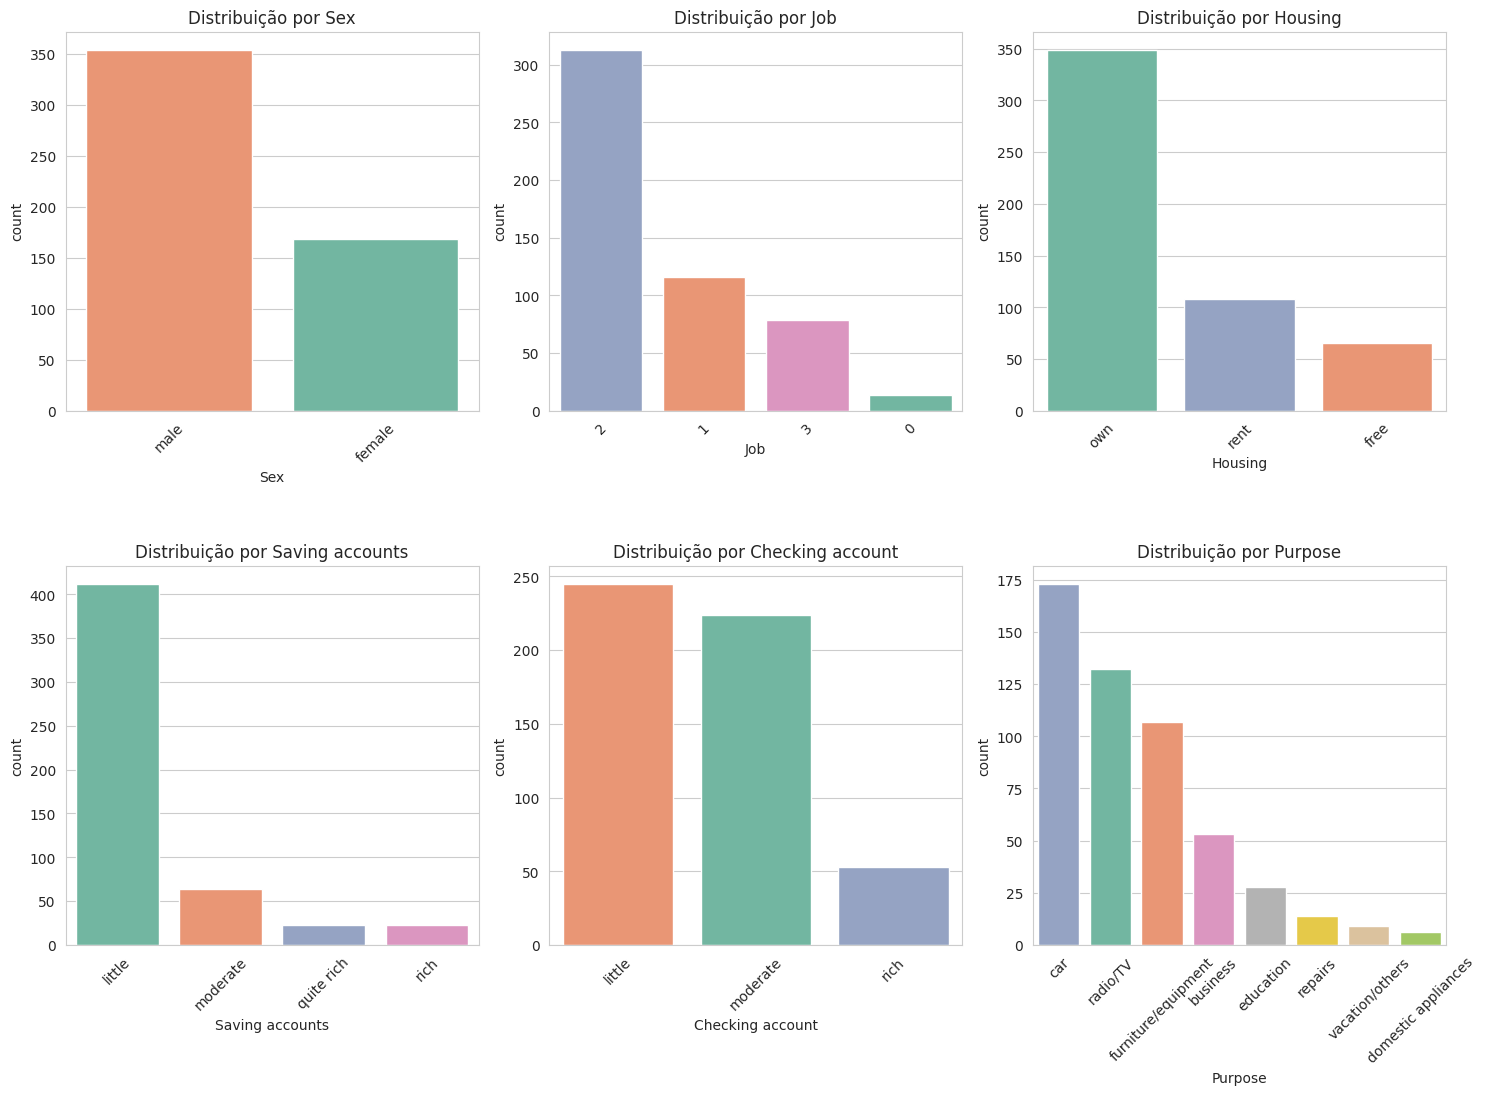


------------------------------------------------



,Age,Job,Credit amount,Duration
Age,1.000000,0.039771,0.082014,0.001549
Job,0.039771,1.000000,0.334721,0.200794
Credit amount,0.082014,0.334721,1.000000,0.613298
Duration,0.001549,0.200794,0.613298,1.000000



------------------------------------------------



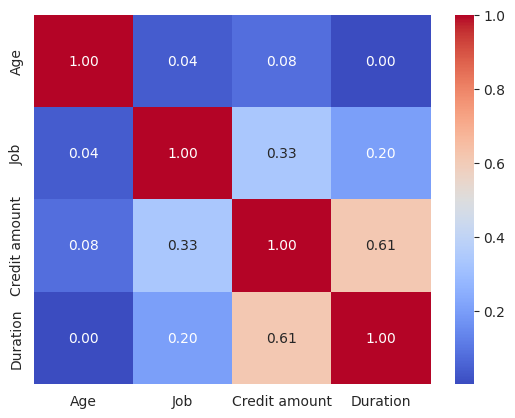

In [7]:
#DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS
plt.figure(figsize=(15, 15))
for i, col in enumerate(categorical_cols):

    plt.subplot(3, 3, i + 1)

    sns.countplot(
        data=df,
        x=col,
        hue=col,
        palette="Set2",
        order=df[col].value_counts().index,
        legend=False
    )

    plt.title(f"Distribuição por {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


#Tabela de Correlação
print("\n------------------------------------------------\n")
corr=df[["Age", "Job", "Credit amount", "Duration"]].corr()
display(corr)
print("\n------------------------------------------------\n")



#MAPA DE CALOR
sns.heatmap (corr, annot= True, cmap ="coolwarm", fmt=".2f")
plt.show ()

In [8]:
#VALOR MÉDIO DO CRÉDITO POR CATEGORIA PROFISSIONAL (JOB)
display(df.groupby("Job")["Credit amount"].mean())


#VALOR MÉDIO DO CRÉDITO POR SEXO
display(df.groupby("Sex")["Credit amount"].mean())

#TABELA DINÂMICA: VALOR DO CRÉDITO POR MORADIA E FINALIDADE
display(df.pivot_table(values="Credit amount", index="Housing", columns="Purpose"))

,Credit amount
Job,
0,1767.857143
1,2250.715517
2,3129.130990
3,5648.784810


,Credit amount
Sex,
female,2937.202381
male,3440.833333


Purpose,business,car,domestic appliances,education,furniture/equipment,radio/TV,repairs,vacation/others
Housing,,,,,,,,
free,4705.000000,5180.314286,NaN,5314.250000,4419.444444,2097.000000,1190.0,7842.666667
own,3725.973684,3120.485437,1333.5,2625.076923,3031.100000,2307.613861,2993.5,10321.833333
rent,6180.833333,3398.285714,NaN,2627.857143,2890.285714,2138.000000,2384.0,NaN


A análise da distribuição das variáveis categóricas permitiu identificar algumas características predominantes no conjunto de dados.

Em relação ao sexo (`Sex`), observa-se uma predominância de clientes do sexo masculino. Na variável `Job` (trabalho), a categoria 2 concentra a maior quantidade de registros, enquanto as demais categorias apresentam frequências menores.

Quanto à moradia (`Housing`), a maioria dos clientes possui imóvel próprio (`own`), seguida por aqueles que residem em imóveis alugados (`rent`) ou sem pagamento de aluguel (`free`).

Na variável `Saving accounts`, destaca-se a concentração de clientes na categoria `little`, indicando uma predominância de registros com pouca poupança. Comportamento semelhante é observado em `Checking account`, na qual as categorias `little` e `moderate` apresentam maior frequência.

Em relação à finalidade dos empréstimos (`Purpose`), a compra de automóveis (`car`) representa a categoria mais frequente, seguida por rádio e televisão (`radio/TV`), móveis e equipamentos (`furniture/equipment`) e negócios (`business`). As demais finalidades apresentam menor participação.

### Análise da Matriz de Correlação

Na análise de correlação, o principal destaque foi a relação positiva entre `Credit amount` e `Duration`, com coeficiente de aproximadamente 0,61. Esse resultado indica que empréstimos de valores mais elevados tendem a estar associados a prazos de pagamento maiores.

As demais relações apresentaram correlações fracas ou muito próximas de zero, com destaque para a variável `Age`, que demonstrou pouca associação linear com as demais variáveis analisadas.



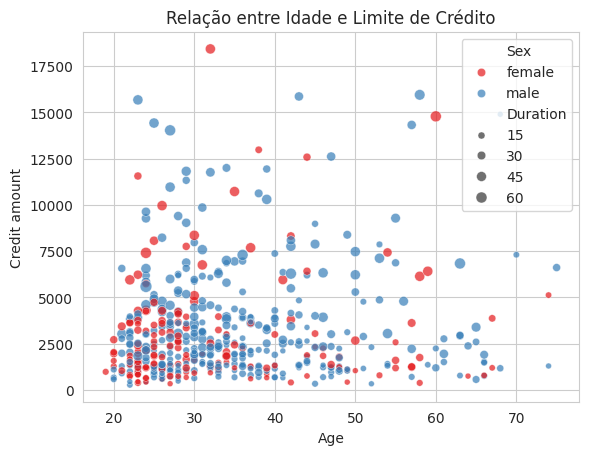

/tmp/ipykernel_16814/2145933147.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data= df, x= "Saving accounts", y="Credit amount", palette="Pastel1")


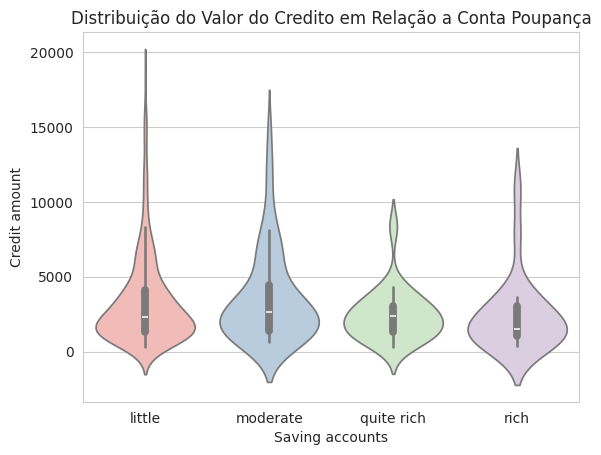

/tmp/ipykernel_16814/2145933147.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Risk", y = col, palette="Pastel2")
/tmp/ipykernel_16814/2145933147.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Risk", y = col, palette="Pastel2")
/tmp/ipykernel_16814/2145933147.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Risk", y = col, palette="Pastel2")


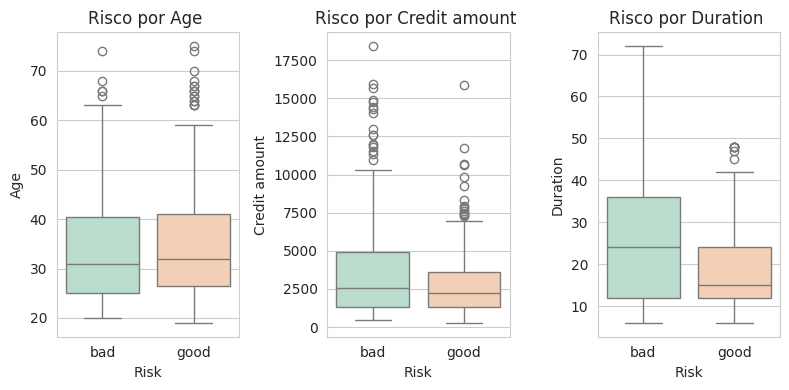

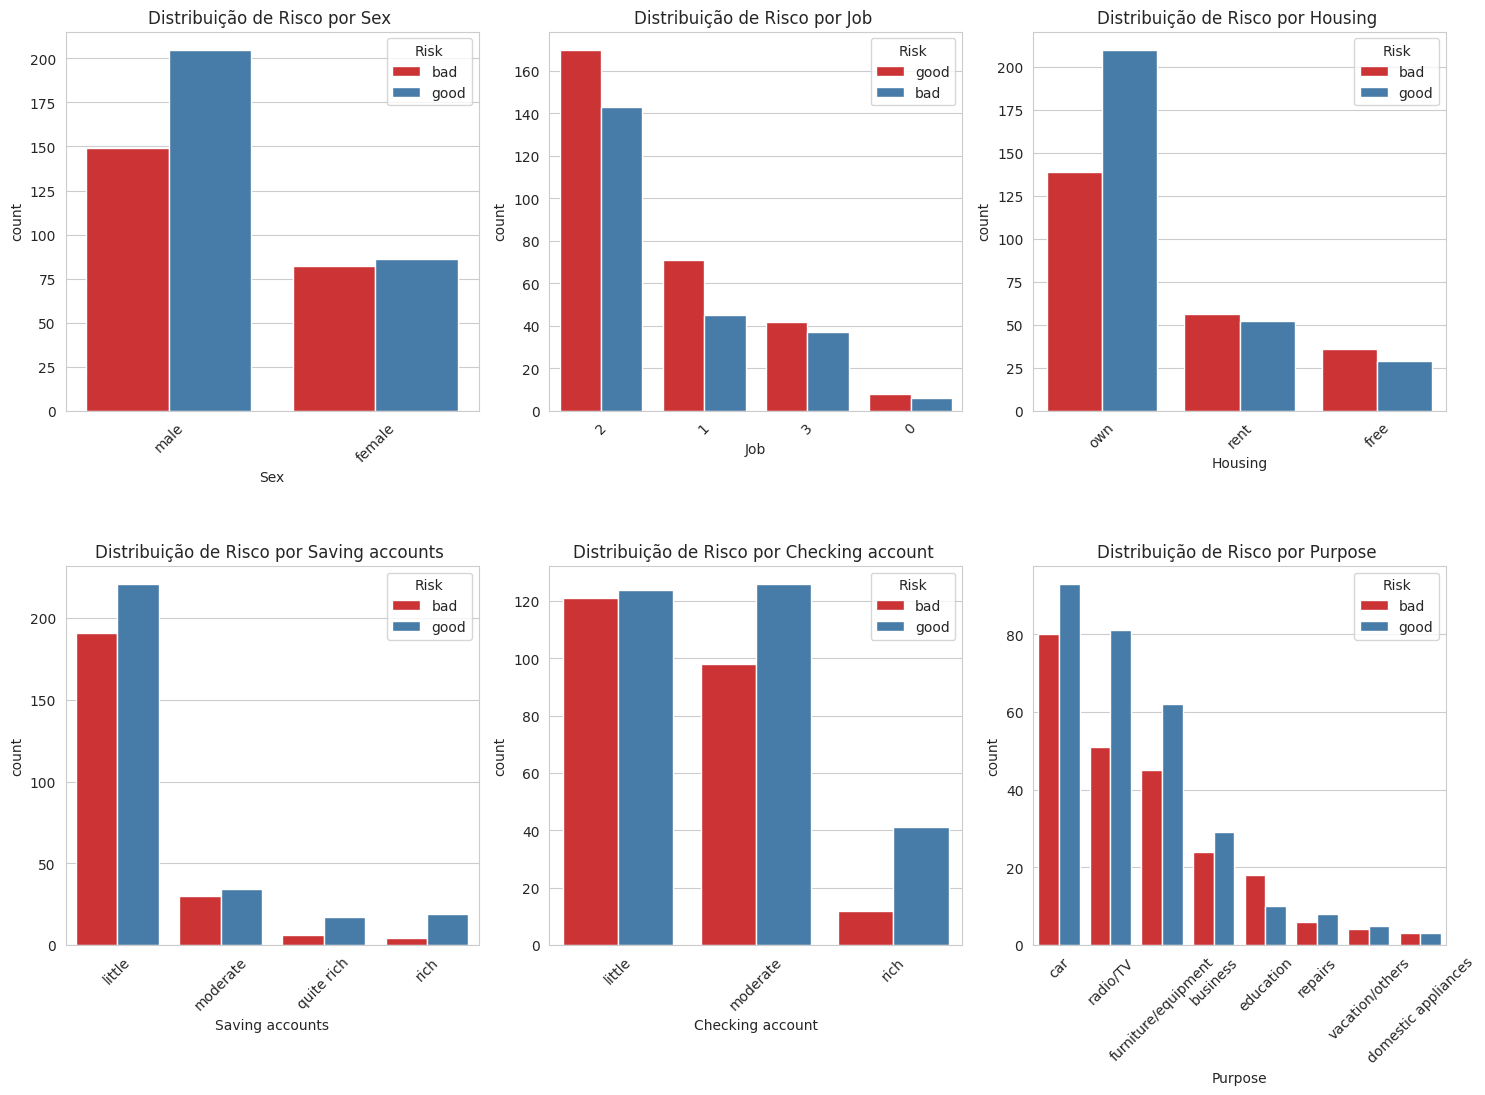

In [9]:
#RELAÇÃO ENTRE IDADE, VALOR DO CRÉDITO E DURAÇÃO

sns.scatterplot(data=df, x="Age", y="Credit amount", hue="Sex", size ="Duration", alpha=0.7, palette="Set1")
plt.title("Relação entre Idade e Limite de Crédito")
plt.show()


#DISTRIBUIÇÃO DO CRÉDITO POR CONTA POUPANÇA
sns.violinplot(data= df, x= "Saving accounts", y="Credit amount", palette="Pastel1")
plt.title("Distribuição do Valor do Credito em Relação a Conta Poupança")
plt.show()


#DISTRIBUIÇÃO DAS VARIÁVEIS NUMÉRICAS POR RISCO
plt.figure(figsize=(8,4))
for i, col in enumerate(["Age","Credit amount", "Duration"]):
  plt.subplot(1,3, i+1)
  sns.boxplot(data=df, x="Risk", y = col, palette="Pastel2")
  plt.title(f"Risco por {col} ")

plt.tight_layout()
plt.show()

#DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS POR RISCO
plt.figure(figsize=(15, 15))
for i, col in enumerate(categorical_cols):
  plt.subplot(3,3, i+1)
  sns.countplot(data = df, x= col, hue="Risk", palette="Set1", order=df[col].value_counts().index)
  plt.title(f"Distribuição de Risco por {col} ")
  plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [10]:
#DISTRIBUIÇÃO PERCENTUAL DA VARIÁVEL RISCO
display(df["Risk"].value_counts(normalize=True) * 100)

#MÉDIA DAS VARIÁVEIS NUMÉRICAS POR CLASSIFICAÇÃO DE RISCO
display(df.groupby("Risk")[["Age", "Credit amount", "Duration"]].mean ())

,proportion
Risk,
good,55.747126
bad,44.252874


,Age,Credit amount,Duration
Risk,,,
bad,34.147186,3881.090909,25.445887
good,35.477663,2800.594502,18.079038


### Conclusão da análise exploratória dos dados

A análise exploratória permitiu identificar características importantes da base de dados, compreender a distribuição das variáveis e observar possíveis relações entre o perfil dos clientes, as operações de crédito e a classificação de risco.


Inicialmente, a variável **Risk** apresentou uma distribuição relativamente equilibrada, com 55,75% dos clientes classificados como Good e 44,25% como Bad.


Na análise das variáveis numéricas, a idade apresentou comportamentos semelhantes entre as classificações, com médias de 34,15 anos para **Bad** e 35,48 anos para **Good**, sem diferenças expressivas entre os grupos.

Na variável **Credit amount**, os clientes classificados como **Bad** apresentam valor médio de crédito de `R$ 3.881,09`, aproximadamente **38,6% superior** ao grupo **Good**, cuja média é de `R$ 2.800,59`. Além disso, o grupo Bad apresenta maior dispersão e valores extremos que chegam a aproximadamente `R$ 18.400`.

A variável **Duration** também demonstrou uma diferença significativa, com duração média de 25,45 meses para **Bad** e 18,08 meses para **Good**. Essa diferença também aparece nas medianas, indicando que os clientes classificados como Bad apresentam, em geral, financiamentos com prazos maiores.

Em relação às variáveis categóricas, observou-se maior concentração de registros masculinos, enquanto a categoria Job 2 representa o maior volume de clientes. Na variável Housing, a categoria own concentra a maior quantidade de registros, com predominância de clientes Good. Já nas categorias rent e free, observa-se uma quantidade ligeiramente superior de clientes Bad. Em **Saving accounts**, a categoria little concentra a maior parte dos registros, enquanto quite rich e rich apresentam menor representatividade e predominância de clientes Good. Na variável **Checking account**, destacou-se a categoria rich, com aproximadamente 41 clientes Good contra 12 Bad. Quanto à variável **Purpose**, as finalidades car, radio/TV e furniture/equipment concentram a maior quantidade de operações, enquanto education apresenta maior quantidade de registros Bad.

A análise da distribuição do valor do crédito em relação às categorias de poupança demonstrou maior dispersão nas categorias little e moderate, com operações que chegam a aproximadamente `R$ 20.000` e `R$ 17.500`, respectivamente. As categorias quite rich e rich apresentam maior concentração de valores inferiores, embora também possuam operações de crédito elevado. Esse comportamento indica que diferentes níveis de poupança estão associados a uma ampla variedade de valores de crédito contratados.

Por fim, a relação entre idade e valor do crédito não apresentou uma tendência linear evidente. A maior concentração de operações está abaixo de `R$ 5.000`, principalmente entre clientes de 20 a 40 anos, mas também foram identificadas operações superiores a `R$ 10.000` em diferentes faixas etárias. A distribuição por sexo demonstrou maior quantidade de registros masculinos, enquanto a duração dos financiamentos apresentou variação entre diferentes idades e valores de crédito.

De modo geral, os resultados destacam **Credit amount e Duration como as variáveis numéricas com diferenças mais expressivas entre as classificações de risco**. Entre as variáveis categóricas, Checking account, Saving accounts e Housing apresentaram padrões que merecem investigação. Essas observações constituem a base para a próxima etapa do projeto, na qual serão realizadas a preparação dos dados e a construção de modelos preditivos, buscando avaliar a contribuição individual e conjunta dessas características para a identificação do risco de crédito.

## 4 -  Etapa de Modelagem

Com a conclusão da Análise Exploratória dos Dados (EDA) e a compreensão das principais características da base, iniciaremos a etapa de Modelagem. Nesta fase, os dados serão utilizados para desenvolver modelos de Machine Learning capazes de identificar padrões e realizar previsões sobre o risco de crédito dos clientes, classificando-os como **Good** ou **Bad**.

Serão selecionadas as variáveis preditoras (*features*) e definida a variável-alvo (*target*). Em seguida, os dados serão divididos em conjuntos de treinamento e teste, e diferentes algoritmos de classificação serão aplicados.

In [11]:
#Separação das Variaveis Target e Features
features = ["Age", "Sex", "Job", "Housing", "Saving accounts", "Checking account", "Credit amount", "Duration"]
target = "Risk"
df_model = df[features+ [target]].copy()
print(df_model.head())

#Codificação das Variáveis Categóricas
cat_cols = df_model.select_dtypes(include="object").columns.drop("Risk")
le_dict={}

for col in cat_cols:
  le = LabelEncoder()
  df_model[col] = le.fit_transform(df_model[col])
  le_dict[col] = le
  joblib.dump(le,f"{col}_encoder.pkl")

le_target=LabelEncoder()
df_model[target] = le_target.fit_transform(df_model[target])
joblib.dump(le_target, "target_encoder.pkl")


#Separação de variáveis de treino e teste
X=df_model.drop(target, axis = 1)
y=df_model[target]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

#Função Auxiliar para os modelos
def train_model(model, param_grid, X_train, y_train, X_test, y_test):
  grid = GridSearchCV(model, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
  grid.fit(X_train, y_train)
  best_model = grid.best_estimator_
  y_pred = best_model.predict(X_test)
  y_prob_bad = best_model.predict_proba(X_test)[:, 0]
  y_test_bad = (y_test == 0).astype(int)
  y_pred_bad = (y_pred == 0).astype(int)
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test_bad, y_pred_bad)
  recall = recall_score(y_test_bad, y_pred_bad)
  f1 = f1_score(y_test_bad, y_pred_bad)
  auc = roc_auc_score(y_test_bad, y_prob_bad)
  return best_model, accuracy, precision, recall, f1, auc, grid.best_params_


   Age     Sex  Job Housing Saving accounts Checking account  Credit amount  \
0   22  female    2     own          little         moderate           5951   
1   45    male    2    free          little           little           7882   
2   53    male    2    free          little           little           4870   
3   35    male    3    rent          little         moderate           6948   
4   28    male    3     own          little         moderate           5234   

   Duration  Risk  
0        48   bad  
1        42  good  
2        24   bad  
3        36  good  
4        30   bad  


## - Regreção logística -

In [12]:

lr = LogisticRegression(random_state=1, class_weight="balanced", max_iter=100)
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"]}

best_lr, acc_lr, prec_lr, rec_lr, f1_lr, auc_lr, params_lr = train_model(lr, lr_param_grid, X_train, y_train, X_test, y_test)

print("Melhor Modelo de Regressão Logística:")
print(f"Acurácia: {acc_lr}")
print(f"Precision: {prec_lr}")
print(f"Recall: {rec_lr}")
print(f"F1-Score: {f1_lr}")
print(f"ROC AUC: {auc_lr}")
print(f"Parâmetros do Melhor Modelo: {params_lr}")

Melhor Modelo de Regressão Logística:
Acurácia: 0.6476190476190476
Precision: 0.6153846153846154
Recall: 0.5217391304347826
F1-Score: 0.5647058823529412
ROC AUC: 0.6750184229918939
Parâmetros do Melhor Modelo: {'C': 0.1, 'solver': 'liblinear'}


 ## - Árvore de Decisão -

In [13]:
dt = DecisionTreeClassifier(random_state=1, class_weight="balanced")
dt_param_grid = {
    "max_depth": [ 3,5,7,10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

best_dt, acc_dt, prec_dt, rec_dt, f1_dt, auc_dt, params_dt = train_model(dt, dt_param_grid, X_train, y_train, X_test, y_test)


print("Melhor Modelo de Árvore de Decisão:")
print(f"Acurácia: {acc_dt}")
print(f"Precision: {prec_dt}")
print(f"Recall: {rec_dt}")
print(f"F1-Score: {f1_dt}")
print(f"ROC AUC: {auc_dt}")
print(f"Parâmetros do Melhor Modelo: {params_dt}")

Melhor Modelo de Árvore de Decisão:
Acurácia: 0.580952380952381
Precision: 0.5208333333333334
Recall: 0.5434782608695652
F1-Score: 0.5319148936170213
ROC AUC: 0.5692704495210021
Parâmetros do Melhor Modelo: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


#- Random Forest -

In [14]:
rf = RandomForestClassifier(random_state=1, class_weight="balanced", n_jobs=-1)
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

best_rf, acc_rf, prec_rf, rec_rf, f1_rf, auc_rf, params_rf = train_model(rf, rf_param_grid, X_train, y_train, X_test, y_test)

print("Melhor Modelo de Random Forest:")
print(f"Acurácia: {acc_rf}")
print(f"Precision: {prec_rf}")
print(f"Recall: {rec_rf}")
print(f"F1-Score: {f1_rf}")
print(f"ROC AUC: {auc_rf}")
print(f"Parâmetros do Melhor Modelo: {params_rf}")


Melhor Modelo de Random Forest:
Acurácia: 0.6190476190476191
Precision: 0.5681818181818182
Recall: 0.5434782608695652
F1-Score: 0.5555555555555556
ROC AUC: 0.673544583640383
Parâmetros do Melhor Modelo: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}


## - Extra Trees Classifier -

In [15]:
et = ExtraTreesClassifier(random_state = 1, class_weight = "balanced", n_jobs = -1)
et_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

best_et, acc_et, prec_et, rec_et, f1_et, auc_et, params_et = train_model(et, et_param_grid, X_train, y_train, X_test, y_test)

print("Melhor Modelo de Extra Trees:")
print(f"Acurácia: {acc_et}")
print(f"Precision: {prec_et}")
print(f"Recall: {rec_et}")
print(f"F1-Score: {f1_et}")
print(f"ROC AUC: {auc_et}")
print(f"Parâmetros do Melhor Modelo: {params_et}")

Melhor Modelo de Extra Trees:
Acurácia: 0.6476190476190476
Precision: 0.5957446808510638
Recall: 0.6086956521739131
F1-Score: 0.6021505376344086
ROC AUC: 0.6912306558585115
Parâmetros do Melhor Modelo: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}


## - XGBoost -

In [16]:
xgb= XGBClassifier(random_state=1, scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(), eval_metric="logloss")
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.7, 1],
    "colsample_bytree": [0.7, 1]
}

best_xgb, acc_xgb, prec_xgb, rec_xgb, f1_xgb, auc_xgb, params_xgb = train_model(xgb, xgb_param_grid, X_train, y_train, X_test, y_test)

print("Melhor Modelo de XGBoost:")
print(f"Acurácia: {acc_xgb}")
print(f"Precision: {prec_xgb}")
print(f"Recall: {rec_xgb}")
print(f"F1-Score: {f1_xgb}")
print(f"ROC AUC: {auc_xgb}")
print(f"Parâmetros do Melhor Modelo: {params_xgb}")

Melhor Modelo de XGBoost:
Acurácia: 0.6476190476190476
Precision: 0.5957446808510638
Recall: 0.6086956521739131
F1-Score: 0.6021505376344086
ROC AUC: 0.7218128224023581
Parâmetros do Melhor Modelo: {'colsample_bytree': 1, 'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.7}


In [17]:
# Comparação dos modelos
comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "XGBoost",
        "Extra Trees",
        "Random Forest",
        "Árvore de Decisão",
        "Regressão Logística"
    ],
    "Acurácia": [acc_xgb, acc_et, acc_rf, acc_dt, acc_lr],
    "Precision (Bad)": [prec_xgb, prec_et, prec_rf, prec_dt, prec_lr],
    "Recall (Bad)": [rec_xgb, rec_et, rec_rf, rec_dt, rec_lr],
    "F1-Score (Bad)": [f1_xgb, f1_et, f1_rf, f1_dt, f1_lr],
    "ROC-AUC": [auc_xgb, auc_et, auc_rf, auc_dt, auc_lr]
})

# Ordenar pelo ROC-AUC, do maior para o menor
comparacao_modelos = comparacao_modelos.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

# Exibir tabela formatada
display(
    comparacao_modelos.style.format({
        "Acurácia": "{:.2%}",
        "Precision (Bad)": "{:.2%}",
        "Recall (Bad)": "{:.2%}",
        "F1-Score (Bad)": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    }).highlight_max(
        subset=["Acurácia", "Precision (Bad)", "Recall (Bad)",
                "F1-Score (Bad)", "ROC-AUC"],
        props="font-weight: bold;"
    )
)


,Modelo,Acurácia,Precision (Bad),Recall (Bad),F1-Score (Bad),ROC-AUC
0,XGBoost,64.76%,59.57%,60.87%,0.6022,0.7218
1,Extra Trees,64.76%,59.57%,60.87%,0.6022,0.6912
2,Regressão Logística,64.76%,61.54%,52.17%,0.5647,0.6750
3,Random Forest,61.90%,56.82%,54.35%,0.5556,0.6735
4,Árvore de Decisão,58.10%,52.08%,54.35%,0.5319,0.5693


### Comparação e seleção dos modelos

Após o treinamento e a avaliação dos cinco algoritmos de classificação, o XGBoost apresentou o melhor desempenho geral, alcançando acurácia de 64,76%, Precision de 59,57%, Recall de 60,87%, F1-Score de 0,6022 e ROC-AUC de 0,7218.

Embora o Extra Trees tenha apresentado os mesmos resultados de acurácia, Precision, Recall e F1-Score, o XGBoost obteve um ROC-AUC superior, indicando maior capacidade de discriminação entre clientes classificados como Good e Bad.

Considerando o objetivo do projeto de identificar clientes com maior risco de inadimplência, o Recall da classe Bad também recebeu atenção especial. Nesse indicador, XGBoost e Extra Trees apresentaram o melhor resultado, identificando aproximadamente 60,87% dos clientes pertencentes a essa classe.

Dessa forma, o XGBoost foi selecionado como o modelo de melhor desempenho nesta etapa, considerando principalmente sua capacidade de discriminação e seu desempenho na identificação de clientes de risco. Entretanto, os resultados ainda indicam oportunidades de melhoria, especialmente na identificação de clientes Bad, o que justifica análises adicionais envolvendo ajuste do limiar de classificação e avaliação dos custos associados aos erros de previsão.

In [19]:
# Gerar probabilidades por validação cruzada no conjunto de treino
modelo_cv = clone(best_xgb)

prob_cv = cross_val_predict(
    modelo_cv,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)

# Identificar a coluna correspondente à classe Bad (0)
indice_bad = np.where(best_xgb.classes_ == 0)[0][0]
prob_bad_cv = prob_cv[:, indice_bad]

# Considerar Bad como classe positiva
y_train_bad = (y_train == 0).astype(int)

# Calcular métricas para diferentes thresholds
thresholds = np.arange(0.20, 0.81, 0.05)

resultados_threshold = []

for threshold in thresholds:

    pred_bad = (prob_bad_cv >= threshold).astype(int)

    resultados_threshold.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train_bad, pred_bad, zero_division=0
        ),
        "Recall": recall_score(
            y_train_bad, pred_bad, zero_division=0
        ),
        "F1-Score": f1_score(
            y_train_bad, pred_bad, zero_division=0
        )
    })

df_threshold = pd.DataFrame(resultados_threshold)

display(
    df_threshold.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1-Score
0,0.20,48.47%,85.41%,0.6184
1,0.25,51.33%,83.24%,0.6351
2,0.30,52.19%,77.30%,0.6231
3,0.35,54.00%,72.97%,0.6207
4,0.40,56.56%,67.57%,0.6158
5,0.45,60.30%,64.86%,0.6250
6,0.50,63.79%,60.00%,0.6184
7,0.55,63.12%,54.59%,0.5855
8,0.60,65.75%,51.89%,0.5801
9,0.65,66.92%,47.03%,0.5524


In [20]:
# Meta mínima de Recall
recall_minimo = 0.75

# Selecionar thresholds que atingem a meta
candidatos = np.where(df_threshold["Recall"].values >= recall_minimo)[0]

if len(candidatos) > 0:

    melhor_indice = candidatos[df_threshold.iloc[candidatos]["Precision"].values.argmax()]

    threshold_escolhido = df_threshold.iloc[melhor_indice]["Threshold"]

    print(f"Threshold escolhido: {threshold_escolhido:.2f}")
    print(f"Precision: {df_threshold.iloc[melhor_indice]['Precision']:.2%}")
    print(f"Recall: {df_threshold.iloc[melhor_indice]['Recall']:.2%}")
    print(f"F1-Score: {df_threshold.iloc[melhor_indice]['F1-Score']:.4f}")

else:
    print("Nenhum threshold atingiu a meta de Recall estabelecida.")

Threshold escolhido: 0.30
Precision: 52.19%
Recall: 77.30%
F1-Score: 0.6231


In [22]:
# Probabilidades de Bad no conjunto de teste
prob_bad_test = best_xgb.predict_proba(X_test)[:, indice_bad]

# Aplicar o novo threshold
pred_bad_threshold = (
    prob_bad_test >= threshold_escolhido
).astype(int)

# Transformar o target real para Bad = 1
y_test_bad = (y_test == 0).astype(int)

# Calcular métricas
acc_threshold = accuracy_score(y_test_bad, pred_bad_threshold)
prec_threshold = precision_score(y_test_bad, pred_bad_threshold)
rec_threshold = recall_score(y_test_bad, pred_bad_threshold)
f1_threshold = f1_score(y_test_bad, pred_bad_threshold)
auc_threshold = roc_auc_score(y_test_bad, prob_bad_test)

print("XGBoost com Threshold Ajustado")
print(f"Threshold: {threshold_escolhido:.2f}")
print(f"Acurácia: {acc_threshold:.4f}")
print(f"Precision (Bad): {prec_threshold:.4f}")
print(f"Recall (Bad): {rec_threshold:.4f}")
print(f"F1-Score (Bad): {f1_threshold:.4f}")
print(f"ROC-AUC: {auc_threshold:.4f}")

print("\nMatriz de Confusão:")
print(confusion_matrix(y_test_bad, pred_bad_threshold))

XGBoost com Threshold Ajustado
Threshold: 0.30
Acurácia: 0.6095
Precision (Bad): 0.5362
Recall (Bad): 0.8043
F1-Score (Bad): 0.6435
ROC-AUC: 0.7218

Matriz de Confusão:
[[27 32]
 [ 9 37]]


### Ajuste do Threshold e avaliação do XGBoost

Após a seleção do XGBoost como modelo candidato, foi realizado o ajuste do limiar de classificação (*threshold*), com o objetivo de melhorar a identificação de clientes classificados como **Bad**, ou seja, aqueles que apresentam maior risco de inadimplência.

Inicialmente, o modelo utilizava o threshold padrão de 0,50. Entretanto, considerando que o objetivo do projeto é identificar o maior número possível de clientes de risco, foram avaliados diferentes limiares de classificação, buscando um equilíbrio entre Precision e Recall.

Com base nos resultados obtidos durante a etapa de validação, foi escolhido o threshold de **0,30**, pois apresentou Precision de 52,19% e Recall de 77,30%, atendendo ao critério experimental estabelecido de alcançar Recall igual ou superior a 75%, com a maior Precision entre os limiares que atingiram essa meta.

Com a aplicação desse limiar no conjunto de teste, o modelo apresentou acurácia de 60,95%, Precision de 53,62%, Recall de 80,43% e F1-Score de 0,6435. O ROC-AUC permaneceu em 0,7218, pois essa métrica avalia a capacidade de discriminação do modelo a partir das probabilidades previstas, independentemente do threshold escolhido.

A matriz de confusão apresentou 37 clientes Bad corretamente identificados, enquanto 9 foram classificados incorretamente como Good. Por outro lado, 32 clientes Good foram classificados incorretamente como Bad, e 27 foram identificados corretamente como Good.

Os resultados demonstram que o threshold de 0,30 aumentou a capacidade do modelo de identificar clientes com maior risco de inadimplência, alcançando Recall de 80,43%. Isso significa que aproximadamente 80% dos clientes pertencentes à classe Bad foram identificados corretamente no conjunto de teste.

Essa melhoria ocorreu em troca de uma redução na Precision e na acurácia, indicando que o modelo passou a classificar mais clientes como Bad, incluindo alguns que pertenciam à classe Good.

Dessa forma, a escolha do threshold de 0,30 prioriza a identificação de clientes potencialmente inadimplentes, reduzindo a quantidade de casos de risco não identificados. O resultado evidencia a importância de ajustar o limiar de classificação de acordo com o objetivo do problema, considerando não apenas o desempenho geral do modelo, mas também os impactos dos diferentes tipos de erro.

In [23]:
# Selecionar o melhor modelo e definir o threshold
melhor_modelo = {
    "modelo": best_xgb,
    "threshold": 0.30
}

# Salvar modelo e threshold em um único arquivo
joblib.dump(melhor_modelo, "Melhor_Modelo.pkl")

['Melhor_Modelo.pkl']

##Análise do impacto financeiro e aplicação do modelo na concessão de crédito.

In [28]:
# Identificar os clientes Bad previstos corretamente
clientes_bad_identificados = (
    (y_test == 0) & (pred_bad == 1)
)

# Somar os valores de crédito desses clientes
exposicao_identificada = X_test.loc[
    clientes_bad_identificados, "Credit amount"
].sum()

print(f"Exposição financeira identificada: {exposicao_identificada:,.2f}")

Exposição financeira identificada: 166,197.00


## Conclusão

O desenvolvimento deste projeto mostrou como o Machine Learning pode ajudar uma instituição financeira a identificar clientes com maior risco de não pagar seus empréstimos, permitindo uma análise de crédito mais cuidadosa.

Com a utilização do modelo XGBoost e a configuração do threshold em 0,30, conseguimos identificar corretamente **37 dos 46 clientes classificados como Bad**, o que representa **80,43% dos clientes de maior risco** presentes na amostra de teste. Em outras palavras, o modelo conseguiu reconhecer aproximadamente 8 de cada 10 clientes que exigiam maior atenção.

Outro resultado importante foi observado ao analisar os clientes que não foram sinalizados pelo modelo. Antes dessa análise, **43,81% dos clientes da amostra eram classificados como Bad**. Entre os clientes que não receberam o alerta do modelo, esse percentual caiu para **25%**, representando uma redução de aproximadamente **42,86% na proporção de clientes de maior risco**.

Na análise financeira, identificamos que os clientes Bad reconhecidos corretamente pelo modelo representavam **166.197 em valores de crédito**. Já os clientes Bad que não foram identificados somavam **17.518**. Esses números mostram o volume de crédito associado aos clientes de maior risco e ajudam a instituição a entender onde deve concentrar sua atenção.

Portanto, a utilização desse modelo pode ajudar a instituição a tomar decisões de crédito mais seguras, identificando clientes que precisam de uma avaliação mais detalhada antes da liberação de um empréstimo. Com isso, a empresa passa a ter melhores condições de controlar os riscos, evitar decisões inadequadas e proteger seus resultados financeiros.

Embora os números apresentados sejam provenientes de uma simulação com dados históricos, os resultados demonstram que o Machine Learning pode ser uma ferramenta importante para melhorar a análise de crédito e apoiar decisões que contribuam para a saúde financeira da instituição.

app

In [ ]:
import streamlit as st
import pandas as pd
import joblib

arquivo = joblib.load("Melhor_Modelo.pkl")
model = arquivo["modelo"]
threshold = arquivo["threshold"]
encoders ={col: joblib.load(f"{col}_encoder.pkl") for col in ["Sex", "Housing", "Saving accounts", "Checking account" ]} #"Purpose"
st.title("Aplicativo de Risco de Crédito")
st.write("Preencha os campos abaixo para verificar o risco de crédito.")

age = st.number_input("Idade", min_value=18, max_value=80, value=30)
sex = st.selectbox("Sexo", ["male", "female"])
job = st.number_input("Profissão (0-3)", min_value=0, max_value=3, value=1)
housing = st.selectbox("Tipo de Moradia", ["own", "rent", "free"])
saving_accounts = st.selectbox("Conta Poupança", ["little", "moderate", "rich","quite rich"])
checking_account = st.selectbox("Conta Corrente", ["little", "moderate", "rich"])
credit_amount = st.number_input("Limite de Crédito", min_value=0, max_value=100000)
duration = st.number_input("Duração do Empréstimo (em meses)", min_value=1, max_value=120)


input_df= pd.DataFrame({
    "Age": [age],
    "Sex": [encoders["Sex"].transform([sex])[0]],
    "Job": [job],
    "Housing": [encoders["Housing"].transform([housing])[0]],
    "Saving accounts": [encoders["Saving accounts"].transform([saving_accounts])[0]],
    "Checking account": [encoders["Checking account"].transform([checking_account])[0]],
    "Credit amount": [credit_amount],
    "Duration": [duration]
})

if st.button("Previsão de Risco"):
  prob_bad = model.predict_proba(input_df)[0, indice_bad]

  if prob_bad >= threshold:
    st.error("Risco Alto")
  else:
    st.success("Risco Baixo")

In [ ]:

import streamlit as st
import pandas as pd
import joblib

# ==========================================================
# 1. CONFIGURAÇÃO DA PÁGINA
# ==========================================================

st.set_page_config(
    page_title="Nexus | Análise de Crédito",
    page_icon="📊",
    layout="wide"
)

# ==========================================================
# 2. IDENTIDADE VISUAL
# ==========================================================

st.markdown("""
<style>
    .block-container {
        padding-top: 2rem;
        padding-bottom: 2rem;
        max-width: 1200px;
    }

    .main-title {
        font-size: 32px;
        font-weight: 700;
        color: #1E293B;
        margin-bottom: 5px;
    }

    .subtitle {
        color: #64748B;
        font-size: 15px;
        margin-bottom: 25px;
    }

    .section-title {
        font-size: 19px;
        font-weight: 600;
        color: #1E293B;
        margin-top: 10px;
        margin-bottom: 15px;
    }

    .result-card {
        padding: 22px;
        border-radius: 12px;
        background-color: #F1F5F9;
        border: 1px solid #E2E8F0;
        margin-top: 15px;
    }

    .risk-high {
        color: #DC2626;
        font-size: 25px;
        font-weight: 700;
    }

    .risk-low {
        color: #15803D;
        font-size: 25px;
        font-weight: 700;
    }

    .small-text {
        color: #64748B;
        font-size: 13px;
    }

    div[data-testid="stMetric"] {
        background-color: #F8FAFC;
        border: 1px solid #E2E8F0;
        padding: 15px;
        border-radius: 10px;
    }

</style>
""", unsafe_allow_html=True)


# ==========================================================
# 3. CARREGAMENTO DO MODELO E DO THRESHOLD
# ==========================================================

arquivo = joblib.load("Melhor_Modelo.pkl")

model = arquivo["modelo"]
threshold = arquivo["threshold"]


# ==========================================================
# 4. CARREGAMENTO DOS ENCODERS
# ==========================================================

encoders = {
    col: joblib.load(f"{col}_encoder.pkl")
    for col in [
        "Sex",
        "Housing",
        "Saving accounts",
        "Checking account"
    ]
}


# ==========================================================
# 5. CABEÇALHO
# ==========================================================

st.markdown(
    '<div class="main-title">Análise de Risco de Crédito</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Sistema de avaliação do perfil de crédito utilizando '
    'Machine Learning e algoritmo XGBoost.'
    '</div>',
    unsafe_allow_html=True
)

st.divider()


# ==========================================================
# 6. FORMULÁRIO DE ENTRADA
# ==========================================================

st.markdown(
    '<div class="section-title">01 | Perfil do solicitante</div>',
    unsafe_allow_html=True
)

col1, col2, col3 = st.columns(3)

with col1:
    age = st.number_input(
        "Idade",
        min_value=18,
        max_value=80,
        value=30
    )

with col2:
    sex = st.selectbox(
        "Sexo",
        ["male", "female"],
        format_func=lambda x: {
            "male": "Masculino",
            "female": "Feminino"
        }[x]
    )

with col3:
    job = st.selectbox(
        "Categoria profissional",
        [0, 1, 2, 3],
        format_func=lambda x: f"Categoria {x}"
    )


st.markdown(
    '<div class="section-title">02 | Perfil financeiro</div>',
    unsafe_allow_html=True
)

col1, col2 = st.columns(2)

with col1:
    housing = st.selectbox(
        "Tipo de moradia",
        ["own", "rent", "free"],
        format_func=lambda x: {
            "own": "Própria",
            "rent": "Alugada",
            "free": "Cedida / Gratuita"
        }[x]
    )

with col2:
    saving_accounts = st.selectbox(
        "Saldo em conta poupança",
        ["little", "moderate", "rich", "quite rich"],
        format_func=lambda x: {
            "little": "Baixo",
            "moderate": "Moderado",
            "rich": "Alto",
            "quite rich": "Muito alto"
        }[x]
    )

checking_account = st.selectbox(
    "Saldo em conta corrente",
    ["little", "moderate", "rich"],
    format_func=lambda x: {
        "little": "Baixo",
        "moderate": "Moderado",
        "rich": "Alto"
    }[x]
)


st.markdown(
    '<div class="section-title">03 | Dados da operação de crédito</div>',
    unsafe_allow_html=True
)

col1, col2 = st.columns(2)

with col1:
    credit_amount = st.number_input(
        "Valor do crédito solicitado (R$)",
        min_value=0,
        max_value=100000,
        value=1000,
        step=100
    )

with col2:
    duration = st.number_input(
        "Prazo do empréstimo (meses)",
        min_value=1,
        max_value=120,
        value=12
    )


st.divider()


# ==========================================================
# 7. EXECUÇÃO DA PREVISÃO
# ==========================================================

if st.button(
    "REALIZAR ANÁLISE DE CRÉDITO",
    use_container_width=True,
    type="primary"
):

    # Codificação das variáveis categóricas
    input_df = pd.DataFrame({
        "Age": [age],
        "Sex": [encoders["Sex"].transform([sex])[0]],
        "Job": [job],
        "Housing": [encoders["Housing"].transform([housing])[0]],
        "Saving accounts": [
            encoders["Saving accounts"].transform([saving_accounts])[0]
        ],
        "Checking account": [
            encoders["Checking account"].transform([checking_account])[0]
        ],
        "Credit amount": [credit_amount],
        "Duration": [duration]
    })

    # Identificar a posição de cada classe
    indice_bad = list(model.classes_).index(0)
    indice_good = list(model.classes_).index(1)

    # Calcular probabilidades
    probabilidades = model.predict_proba(input_df)[0]

    prob_bad = probabilidades[indice_bad]
    prob_good = probabilidades[indice_good]

    # Aplicar threshold ajustado
    if prob_bad >= threshold:
        resultado = "RISCO DE CRÉDITO ELEVADO"
        classificacao = "Bad"
    else:
        resultado = "RISCO DE CRÉDITO REDUZIDO"
        classificacao = "Good"

    # ======================================================
    # 8. RESULTADO DA ANÁLISE
    # ======================================================

    st.divider()

    st.markdown(
        '<div class="section-title">Resultado da avaliação</div>',
        unsafe_allow_html=True
    )

    if classificacao == "Bad":
        st.error(resultado)
        st.write(
            "O modelo identificou uma probabilidade de crédito ruim "
            "igual ou superior ao limite de classificação estabelecido."
        )
    else:
        st.success(resultado)
        st.write(
            "O modelo identificou uma probabilidade de crédito ruim "
            "inferior ao limite de classificação estabelecido."
        )

    # Indicadores principais
    col1, col2, col3 = st.columns(3)

    with col1:
        st.metric(
            "Probabilidade de crédito ruim",
            f"{prob_bad:.2%}"
        )

    with col2:
        st.metric(
            "Probabilidade de crédito bom",
            f"{prob_good:.2%}"
        )

    with col3:
        st.metric(
            "Threshold utilizado",
            f"{threshold:.0%}"
        )

    # ======================================================
    # 9. INDICADOR VISUAL DE RISCO
    # ======================================================

    st.markdown("### Indicador de risco")

    st.progress(float(prob_bad))

    st.caption(
        f"Probabilidade estimada de crédito ruim: {prob_bad:.2%}"
    )

    # ======================================================
    # 10. RESUMO DA ANÁLISE
    # ======================================================

    with st.expander("Visualizar dados analisados"):

        resumo = pd.DataFrame({
            "Informação": [
                "Idade",
                "Sexo",
                "Categoria profissional",
                "Tipo de moradia",
                "Poupança",
                "Conta corrente",
                "Valor do crédito",
                "Prazo"
            ],
            "Valor informado": [
                f"{age} anos",
                "Masculino" if sex == "male" else "Feminino",
                f"Categoria {job}",
                housing,
                saving_accounts,
                checking_account,
                f"R$ {credit_amount:,.2f}",
                f"{duration} meses"
            ]
        })

        st.dataframe(
            resumo,
            use_container_width=True,
            hide_index=True
        )

    # ======================================================
    # 11. AVISO
    # ======================================================

    st.info(
        "Esta avaliação é uma estimativa produzida por um modelo "
        "experimental de Machine Learning. O resultado não representa "
        "uma decisão definitiva de concessão ou recusa de crédito."
    )


# ==========================================================
# 12. RODAPÉ
# ==========================================================

st.divider()

st.markdown(
    '<div style="text-align:center; color:#94A3B8; font-size:12px;">'
    'Sistema demonstrativo de análise de risco de crédito | '
    'Machine Learning com XGBoost'
    '</div>',
    unsafe_allow_html=True
)
